# Step 2 - Work on the Mid-Term Project / Report

# Introduction

Problem Statement: 

For our problem statement, we decided to hone in and delve deep into two specific research questions of the Olympics dataset.
Those being, 'Do physical attributes predict medal success, and does this vary by sport?' and 'Is there a measurable host-country advantage?'

This is particularly of interest, due to the fact that this specific dataset spans over 120 years and could lead to interesting insights such as there not being one specific answer and it shifting or fluctuating over time. This could also lead to other observations and insights as maybe other factors play a role in there being a host-country advantage or physical attributes predicting medal success.

Approach & Analysis:

Using the 'olympics.csv' dataset, a simple way to determine if there is a host-country advantage is using a before-and-after bar chart exmaining the success of host-countries and medals won to see if there is a correlation. To eliminate the possibility of biased data or the sample size being too small, we can construct several (4-6) bar charts to see if there is a true correlation.

For the question of 'Do physical attributes predict medal success, and does this vary by sport?', we first must clean the dataset by filtering and cleaning the rows, handling missing values, and ensuring the numeric columns are properly formatted to prevent any errors during data visualization. Some data visualization techniques we could use and would make for strong insightful discovery would be scatterplots, histograms, and boxplots. These techniques allow to see a correlation between variables such as height, weight, medal, and sport. We would, of course, construct several charts and graphs to maintain a sound analysis.

We plan for our analysis will benefit the use by providing indisputable evidence that these two research questions explain activity that occurs during the Olympics, and could provide insight to overlooked details of the Olympics that could prove to be of more importance than once thought.


# Required Packages

In [2]:
import pandas as pd
# to load CSV files, also to clean and filter data
import numpy as np
# helps with numerical operations with numerical data
import matplotlib.pyplot as plt
# to create data visualizations and graphs
import seaborn as sns
# building plots and high-level plots

# Section 3: Data Preparation

### 3.1 & 3.2 Data Source and Explanation
* **Original Source:** [Kaggle - 120 years of Olympic history: athletes and results](https://www.kaggle.com/datasets/heesoo37/120-years-of-olympic-history-athletes-and-results)
* **Description:** This dataset was collected from `sports-reference.com` in May 2018. It contains **271,116 rows and 15 columns** covering 120 years of Summer and Winter Olympic Games (Athens 1896 to Rio 2016). Each row represents an individual athlete competing in a specific Olympic event.
* **Peculiarities & Missing Values:**
  * `medal` has `NaN` for 85.3% of rows because non-medalists are recorded as `NaN` rather than missing data.
  * `height` (22.2% missing), `weight` (23.2% missing), and `age` (3.5% missing) have missing values concentrated in pre-1960 games.
  * There are 1,385 exact duplicate rows (primarily from early Art Competitions).

### 3.3 & 3.4 Data Importing and Cleaning
1. Suppress any library warnings for a clean report (Section 2.2).
2. Load `olympics.csv` and drop the 1,385 exact duplicate rows using `.drop_duplicates()`.
3. Replace `NaN` in the `medal` column with `"No Medal"` and create a binary indicator `won_medal` (`1` = medaled, `0` = no medal).
4. Filter out rows missing `age`, `height`, or `weight` using `.dropna()` so that physical attribute analyses are complete and accurate.

In [3]:
import os
import warnings
warnings.filterwarnings("ignore") # 2.2: Suppress warnings

# Load dataset
csv_path = "data/olympics.csv" if os.path.exists("data/olympics.csv") else "olympicsdata-main/data/olympics.csv"
df = pd.read_csv(csv_path)

# Clean data: drop duplicates, handle medal NaNs, and filter complete physical records
clean_df = df.drop_duplicates().copy()
clean_df["medal"] = clean_df["medal"].fillna("No Medal")
clean_df["won_medal"] = np.where(clean_df["medal"] == "No Medal", 0, 1)

phys_df = clean_df.dropna(subset=["age", "height", "weight"]).copy()

print("Original rows:", len(df))
print("Cleaned rows (no duplicates):", len(clean_df))
print("Rows with complete physical attributes:", len(phys_df))

# 3.4: Condensed view of the final cleaned dataset (Table 1)
phys_df.head()

Original rows: 271116
Cleaned rows (no duplicates): 269731
Rows with complete physical attributes: 206152


,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal,won_medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,No Medal,0
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,No Medal,0
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,No Medal,0
5,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,"Speed Skating Women's 1,000 metres",No Medal,0
6,5,Christine Jacoba Aaftink,F,25.0,185.0,82.0,Netherlands,NED,1992 Winter,1992,Winter,Albertville,Speed Skating,Speed Skating Women's 500 metres,No Medal,0


**Explanation of Table 1:** The condensed table above shows the first 5 rows of our cleaned dataset (`phys_df`), where exact duplicates and incomplete physical records have been removed, and `won_medal` clearly encodes medal outcomes (`0` or `1`).

### 3.5 Summary of Key Variables
* **`age`:** Athlete age in years (mean: 25.06 years, ranging from 11 to 71).
* **`height`:** Athlete height in centimeters (mean: 175.34 cm, SD: 10.52 cm).
* **`weight`:** Athlete weight in kilograms (mean: 70.69 kg, SD: 14.35 kg).
* **`year`:** Olympic Games year (ranging from 1896 to 2016).
* **`won_medal`:** Binary outcome variable (mean: 0.15, indicating ~15% of athlete-event entries resulted in a medal).

In [4]:
# 3.5: Summary statistics table of key numerical variables (Table 2)
phys_df[["age", "height", "weight", "year", "won_medal"]].describe().round(2)

,age,height,weight,year,won_medal
count,206152.00,206152.00,206152.00,206152.00,206152.00
mean,25.05,175.37,70.69,1989.68,0.15
std,5.48,10.55,14.34,20.13,0.35
min,11.00,127.00,25.00,1896.00,0.00
25%,21.00,168.00,60.00,1976.00,0.00
50%,24.00,175.00,70.00,1992.00,0.00
75%,28.00,183.00,79.00,2006.00,0.00
max,71.00,226.00,214.00,2016.00,1.00


**Explanation of Table 2:** The summary table provides descriptive statistics (count, mean, standard deviation, min, quartiles, and max) for the 206,152 complete athlete-event records.

---

# Section 4: Exploratory Data Analysis

### 4.1 & 4.2 Exploring Physical Attributes and Host-Country Advantage
To uncover insights for our two research questions while staying within the 8-item limit (2 tables above + 4 figures below = 6 total), we use **histograms**, **boxplots**, **scatterplots**, and **bar charts**.

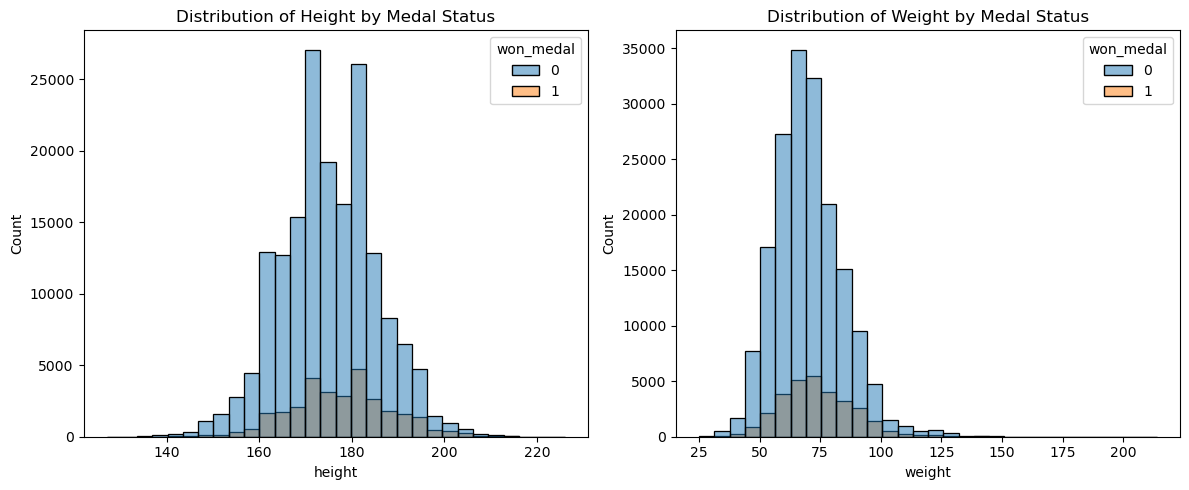

In [5]:
# Figure 1: Histograms of Height and Weight by Medal Status
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=phys_df, x="height", hue="won_medal", bins=30, ax=ax[0])
ax[0].set_title("Distribution of Height by Medal Status")

sns.histplot(data=phys_df, x="weight", hue="won_medal", bins=30, ax=ax[1])
ax[1].set_title("Distribution of Weight by Medal Status")

plt.tight_layout()
plt.show()

**Explanation of Figure 1:** Both height and weight follow a roughly bell-shaped distribution centered near 175 cm and 70 kg. Across all sports combined, medalists (`won_medal = 1`) and non-medalists (`won_medal = 0`) have heavily overlapping distributions, showing that body size alone does not universally guarantee a medal without accounting for the specific sport.

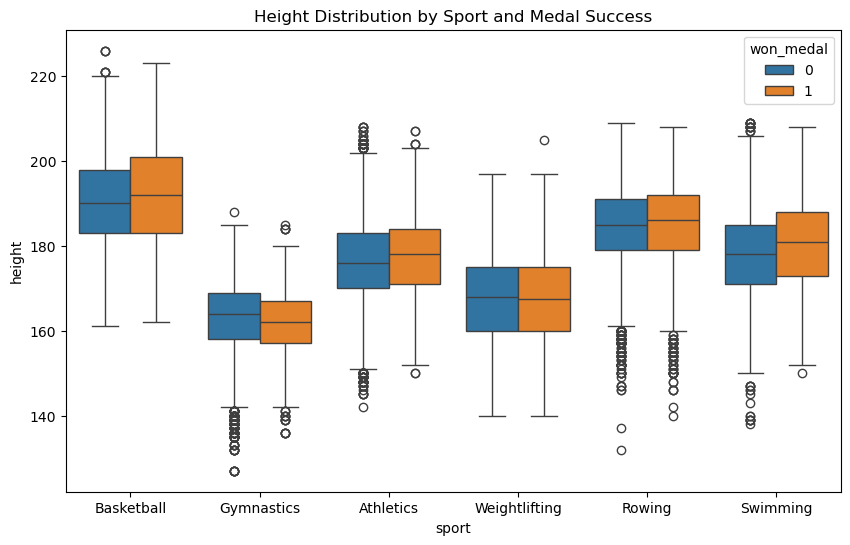

In [6]:
# Filter 6 major sports to compare physical attributes across disciplines
major_sports = ["Basketball", "Rowing", "Swimming", "Athletics", "Weightlifting", "Gymnastics"]
sport_df = phys_df[phys_df["sport"].isin(major_sports)]

# Figure 2: Boxplot of Height across Sports by Medal Status
plt.figure(figsize=(10, 6))
sns.boxplot(data=sport_df, x="sport", y="height", hue="won_medal")
plt.title("Height Distribution by Sport and Medal Success")
plt.show()

**Explanation of Figure 2:** Grouping by sport reveals clear differences. Basketball and Rowing athletes are the tallest (median > 185 cm), and medalists in these sports have a higher median height than non-medalists. In contrast, Gymnastics and Weightlifting favor shorter stature (median < 168 cm), where gymnastics medalists are slightly shorter on average than non-medalists.

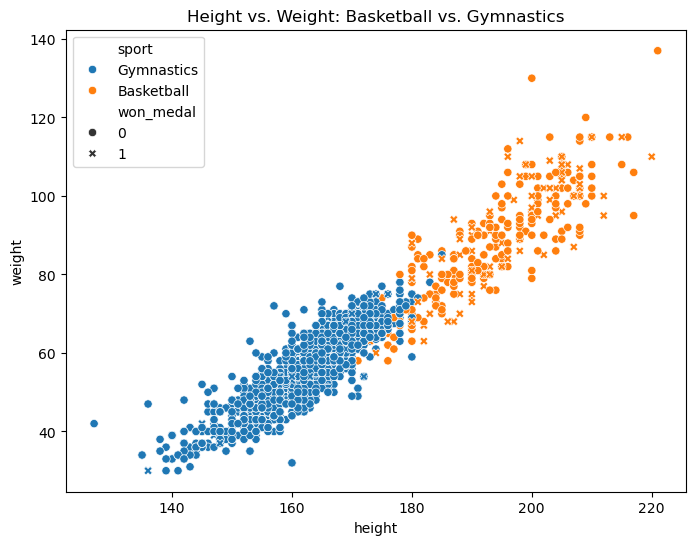

In [7]:
# Sample 2,000 records from Basketball and Gymnastics for a clean scatterplot
bg_df = phys_df[phys_df["sport"].isin(["Basketball", "Gymnastics"])].sample(2000, random_state=42)

# Figure 3: Scatterplot of Height vs. Weight
plt.figure(figsize=(8, 6))
sns.scatterplot(data=bg_df, x="height", y="weight", hue="sport", style="won_medal")
plt.title("Height vs. Weight: Basketball vs. Gymnastics")
plt.show()

**Explanation of Figure 3:** The scatterplot demonstrates a strong positive correlation between height and weight while highlighting how different sports require distinct body types: Basketball athletes cluster in the upper-right (tall and heavy), whereas Gymnastics athletes cluster in the lower-left (short and light).

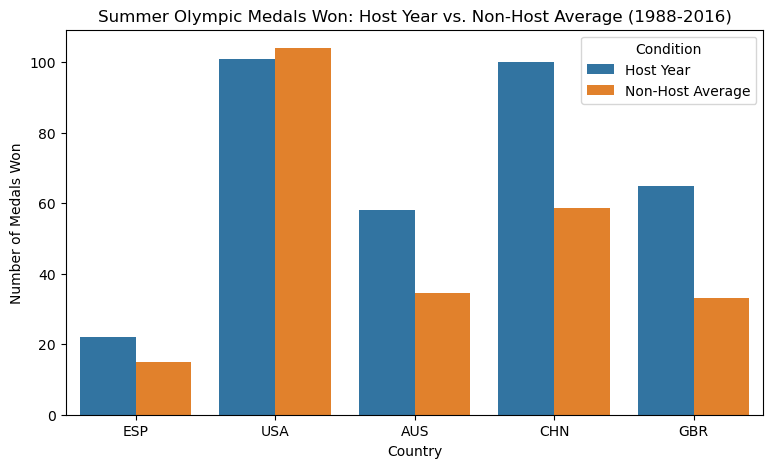

In [8]:
# Deduplicate team medals so team events count as 1 medal per country
medals_only = clean_df[clean_df["won_medal"] == 1].drop_duplicates(subset=["games", "event", "noc", "medal"])

# Compare 5 Summer Olympic Host Countries: Host Year vs. Non-Host Average (1988-2016)
modern_summer = medals_only[(medals_only["season"] == "Summer") & (medals_only["year"] >= 1988)]
hosts = {"ESP": 1992, "USA": 1996, "AUS": 2000, "CHN": 2008, "GBR": 2012}

host_records = []
for noc, host_year in hosts.items():
    country_medals = modern_summer[modern_summer["noc"] == noc].groupby("year").size()
    host_count = country_medals.get(host_year, 0)
    other_avg = country_medals[country_medals.index != host_year].mean()
    
    host_records.append({"Country": noc, "Condition": "Host Year", "Medals": host_count})
    host_records.append({"Country": noc, "Condition": "Non-Host Average", "Medals": other_avg})

host_compare_df = pd.DataFrame(host_records)

# Figure 4: Bar Chart of Host-Country Advantage
plt.figure(figsize=(9, 5))
sns.barplot(data=host_compare_df, x="Country", y="Medals", hue="Condition")
plt.title("Summer Olympic Medals Won: Host Year vs. Non-Host Average (1988-2016)")
plt.ylabel("Number of Medals Won")
plt.show()

**Explanation of Figure 4:** The bar plot compares total medals won by five host countries (Spain 1992, USA 1996, Australia 2000, China 2008, and Great Britain 2012) during their host year against their average in non-host Summer Games (1988–2016). Every host nation won substantially more medals when hosting.

---

### 4.3 Questions Answered by Our Findings
1. **Do physical attributes predict medal success, and does this vary by sport?**
   * **Answer:** Physical attributes strongly differentiate athletes across sports (Figures 2 & 3), and their relationship with winning a medal depends on the sport. Taller builds correspond to higher medal success in Basketball, Rowing, and Swimming, while shorter, compact builds are favored in Gymnastics.
2. **Is there a measurable host-country advantage?**
   * **Answer:** Yes. Figure 4 provides clear visual evidence that countries win significantly more medals in the year they host the Summer Olympics compared to their non-host average.

### 4.4 Unanswered Questions and Plan for Final Project Report
* **Unanswered Questions:** Our exploratory charts do not yet separate *delegation size* (hosts automatically qualify more athletes) from true *home-field advantage*, nor do they provide exact probability estimates for medaling based on height and weight.
* **Plan for Final Report:** In the final report, we will normalize medal counts by delegation size (medals per 100 athletes) and fit a logistic regression model within each sport to test how strongly height, weight, and age predict medal probabilities.